<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/05_delta_rule.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 5 · The Delta Rule & Gradient Descent

*Neural Network Lab — lesson 5 of 8 · about 30 minutes*

### 🎯 Learning objectives
By the end of this lesson you will be able to:

1. derive the delta rule as gradient descent on the squared error $E = \tfrac12(d-o)^2$;
2. train a continuous (sigmoid) perceptron and read a learning curve;
3. explain how the learning constant trades speed against stability;
4. contrast the delta rule with the discrete perceptron rule from Lesson 4.

**Prerequisites:** Lessons 2 and 4; the chain rule.

In [1]:
# ── Setup: runs locally and on Google Colab ──────────────────────────────
try:
    import nnlab
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## 1 · Learning as going downhill

The perceptron rule only knows *whether* it was wrong. If the neuron uses a smooth activation we can
ask *how* wrong it was and in which direction to move. Define the error for one pattern

$$E = \tfrac12\,(d - o)^2, \qquad o = f(net), \qquad net = \mathbf{w}^\top\mathbf{x}.$$

Gradient descent moves the weights a small step against the gradient, $\Delta\mathbf{w} = -c\,\nabla_{\mathbf{w}}E$.
By the chain rule,

$$
\frac{\partial E}{\partial \mathbf{w}}
= \frac{\partial E}{\partial o}\,\frac{\partial o}{\partial net}\,\frac{\partial net}{\partial \mathbf{w}}
= -(d - o)\, f'(net)\, \mathbf{x},
$$

which gives the **delta rule** (Widrow & Hoff, 1960; here with a sigmoid):

$$
\boxed{\Delta\mathbf{w} = c\,(d - o)\,f'(net)\,\mathbf{x}
= c\,(d - o)\,\tfrac{\lambda}{2}(1 - o^2)\,\mathbf{x}}
$$

using the bipolar-sigmoid derivative from Lesson 2. The quantity $\delta = (d - o) f'(net)$ is the
“delta” that gives the rule its name — and it is exactly what backpropagation will pass backwards in Lesson 6.

## 2 · Worked example

We reuse the training set of Lesson 4 so the two rules can be compared directly:
$\mathbf{w}^1 = [1,\ -1,\ 0,\ 0.5]$, $c = 0.1$, $\lambda = 1$.

**Step 1 by hand:** $net = 2.5$, $o = \frac{2}{1+e^{-2.5}} - 1 \approx 0.848$,
$f'(net) = \tfrac12(1 - 0.848^2) \approx 0.140$, and
$\Delta\mathbf{w} = 0.1 \cdot (-1 - 0.848) \cdot 0.140 \cdot \mathbf{x}_1 \approx -0.0259\,\mathbf{x}_1$.

In [2]:
from nnlab.learning_rules import delta_rule, perceptron

w0 = [1, -1, 0, 0.5]
X = [[1, -2, 0, -1],
     [0, 1.5, -0.5, -1],
     [-1, 1, 0.5, -1]]
d = [-1, -1, 1]

one_epoch = delta_rule(w0, X, d, c=0.1, epochs=1)
one_epoch.print_steps(precision=4)

initial w = [ 1.  -1.   0.   0.5]
epoch 1 · x1:  net = +2.5000  o = +0.8483  d = -1  ->  w = [ 0.9741 -0.9482  0.      0.5259]
epoch 1 · x2:  net = -1.9482  o = -0.7505  d = -1  ->  w = [ 0.9741 -0.9563  0.0027  0.5314]
epoch 1 · x3:  net = -2.4604  o = -0.8426  d = +1  ->  w = [ 0.9474 -0.9296  0.0161  0.5046]


Compare with Lesson 4: the perceptron made one large jump ($\pm 0.2\,\mathbf{x}$), the delta rule
makes small steps whose size depends on how far $o$ is from $d$ **and** how steep the sigmoid is.

## 3 · Training to a tolerance

In [3]:
trained = delta_rule(w0, X, d, c=0.1, epochs=5000, tol=0.01)
print(f"total error < 0.01 after {trained.n_epochs} epochs")
print("final weights:", trained.weights)

from nnlab.activations import bipolar_sigmoid
print("outputs:", bipolar_sigmoid(np.asarray(X) @ trained.weights), " targets:", d)

total error < 0.01 after 594 epochs
final weights: [-2.997 -0.197  2.901  1.224]
outputs: [-0.957 -0.902  0.908]  targets: [-1, -1, 1]


Notice the outputs approach $\pm 1$ but never reach them: a sigmoid only hits its asymptotes at
$net = \pm\infty$. That is why we stop at a **tolerance** instead of waiting for zero error.

## 4 · The learning constant: speed vs stability

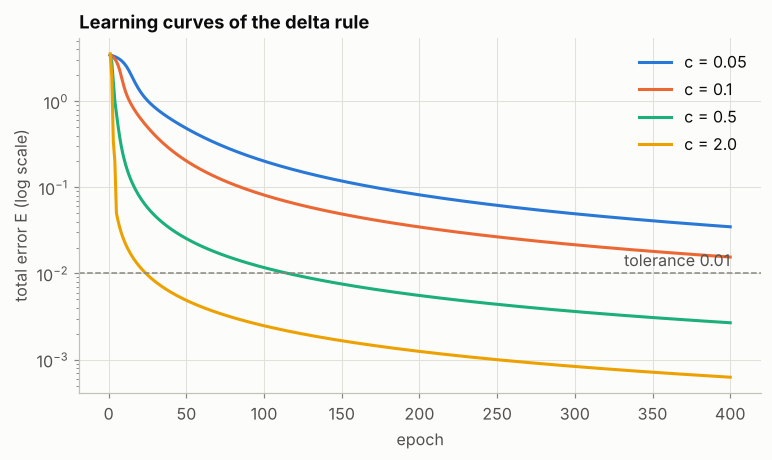

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for c in [0.05, 0.1, 0.5, 2.0]:
    h = delta_rule(w0, X, d, c=c, epochs=400)
    ax.plot(range(1, len(h.epoch_errors) + 1), h.epoch_errors, label=f"c = {c}")
ax.set(yscale="log", xlabel="epoch", ylabel="total error E (log scale)",
       title="Learning curves of the delta rule")
ax.axhline(0.01, color="#898781", ls="--", lw=1)
ax.text(400, 0.011, "tolerance 0.01", ha="right", va="bottom", color="#52514e")
ax.legend()
plt.show()

A larger $c$ gets down the error surface faster, but each step is a linear extrapolation of a curved
surface: when $c$ is too large the steps overshoot. For this small, well-behaved problem every value
above still works, but on harder problems a too-large $c$ makes the error oscillate or diverge.

## 5 · Perceptron rule vs delta rule

| | Perceptron rule | Delta rule |
|---|---|---|
| activation | discrete $\operatorname{sgn}$ | continuous sigmoid |
| update | $c\,(d - o)\,\mathbf{x}$ | $c\,(d - o)\,f'(net)\,\mathbf{x}$ |
| learns from | mistakes only | every pattern, in proportion to the error |
| stops when | zero mistakes | error below a tolerance |
| non-separable data | never settles | settles at a least-error compromise |
| extends to hidden layers? | no | **yes → backpropagation** |

## 6 · Try it yourself

1. Change $\lambda$ to 2 and 0.5 in `delta_rule(..., lam=...)`. How do the number of epochs change, and why?
2. Run the delta rule on the bipolar XOR data from Lesson 4. Plot the error curve. Where does it level off?

**❓ Exercise answers**

<details><summary>Show answer</summary>

1. A steeper sigmoid (larger $\lambda$) has a larger derivative near $net = 0$ and saturates sooner, so early steps are bigger but steps become tiny once $|net|$ is large. Measure it — the answer depends on the balance of those two effects.
2. The error stops decreasing at a non-zero value: the neuron finds the best compromise boundary it can, but no single line separates XOR.

</details>

## 📌 Summary

- The delta rule is gradient descent on the squared error: Δw = c(d − o)f′(net)x.
- Updates are proportional to the error and to the slope of the activation.
- The learning constant trades speed of convergence against stability.
- The local error signal δ = (d − o)f′(net) is the building block of backpropagation.

**Next →** [Lesson 6 · Backpropagation: Solving XOR](06_backpropagation_xor.ipynb)

---

#### References
- Widrow, B., & Hoff, M. E. (1960). Adaptive switching circuits. *IRE WESCON Convention Record*, 4, 96–104.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.